# Linear regression from scratch with NumPy

I wrote linear regression with gradient descent in NumPy and compared it with scikit-learn. After that there are some experiments with outliers, polynomial features, regression metrics, feature engineering and underfitting vs overfitting.

# Handmade Linear Regression

In [1]:
#imports
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import datasets

In [2]:
#init
lr = 0.1
n_iters=1000


In [3]:
# Create Dataset
X, y = datasets.make_regression(n_samples=300, n_features=1, noise=20, random_state=41)

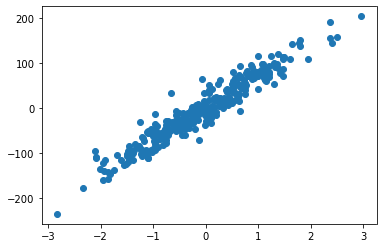

In [4]:
plt.scatter(X,y)

In [6]:
class LinearRegression:
    def __init__(self, learning_rate=0.1, n_iters=1000):
        self.lr = learning_rate
        self.n_iters = n_iters
        self.weights = None
        self.bias = None
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        for _ in range(self.n_iters):
            y_predicted = np.dot(X, self.weights) + self.bias
            
            # compute gradients
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)
            
            # update parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
            
        return self.weights, self.bias
    
    def predict(self, X):
        y_approximated = np.dot(X, self.weights) + self.bias
        return y_approximated

In [7]:
model = LinearRegression()

In [8]:
# Train
weights,bias = model.fit(X, y)

In [9]:
weights,bias

(array([69.91312741]), 1.4766201812023232)

In [10]:
def plot_regression(X, y, model, title):
    y_pred = model.predict(X)
    
    
    plt.figure(figsize=(10, 6))
    plt.scatter(X, y, color='#2ecc71', alpha=0.5, label='Actual data')
    plt.plot(X, y_pred, color='#e74c3c', label=f'Predicted')
    
    plt.title(title)
    plt.xlabel('X')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

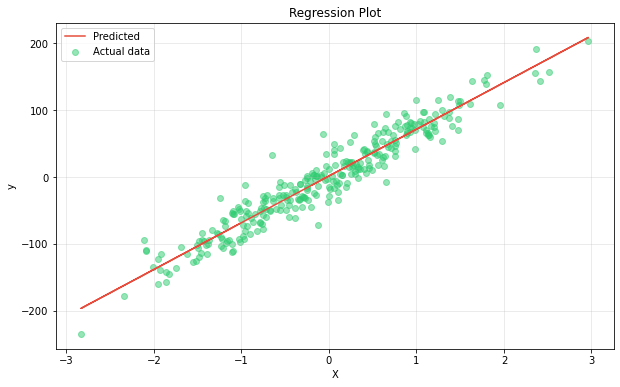

In [11]:
plot_regression(X,y,model,'Regression Plot')

# Scikit - Learn (sklearn) Linear Regression

In [12]:
from sklearn.linear_model import LinearRegression

In [13]:
regression = LinearRegression()
regression.fit(X, y)

LinearRegression()

In [16]:
regression.coef_

array([69.91312741])

In [17]:
regression.intercept_

1.4766201812023265

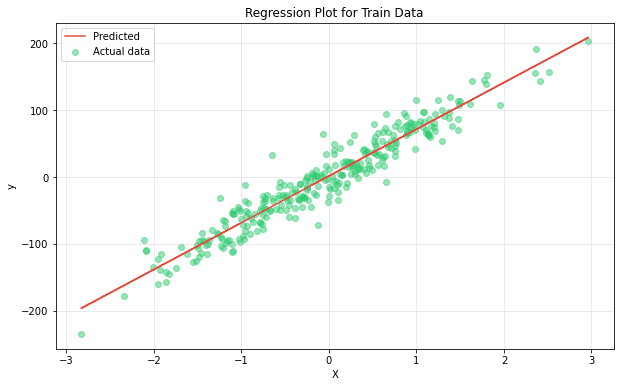

In [15]:
plot_regression(X,y,regression,'Regression Plot for Train Data')

# With Outliers

In [20]:
def create_bad_regression_dataset(n_samples,n_features,noise, random_state):
    X, y = datasets.make_regression(n_samples=n_samples, n_features=n_features, noise=noise, random_state=random_state)
    X = X.tolist()
    y = y.tolist()
    for i in range(2,10):
        X.append([i])
        y.append(-100)
    X = np.array(X)
    y =  np.array(y)
    return X,y

In [21]:
X_bad,y_bad = create_bad_regression_dataset(300,1,20,1234)

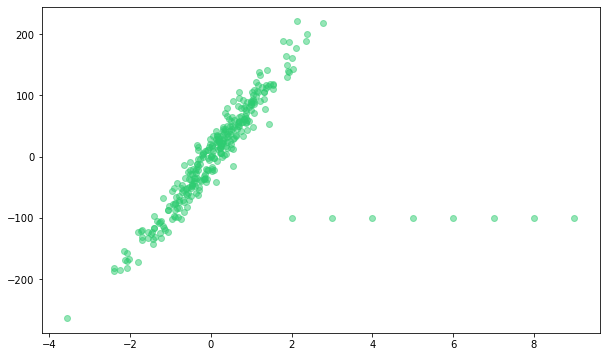

In [22]:
plt.figure(figsize=(10, 6))
plt.scatter(X_bad, y_bad, color='#2ecc71', alpha=0.5, label='Bad data')
plt.show()

In [23]:
regression = LinearRegression()
regression.fit(X_bad, y_bad)

LinearRegression()

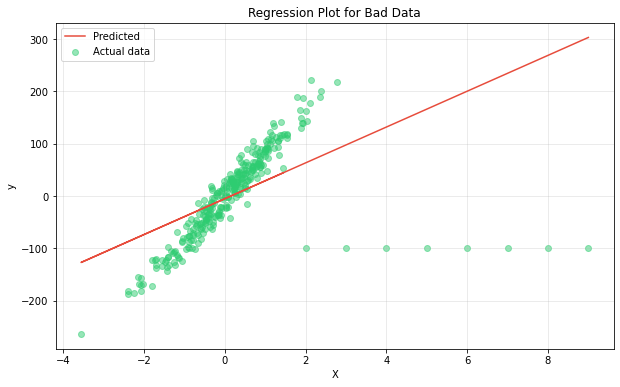

In [24]:
plot_regression(X_bad,y_bad,regression,'Regression Plot for Bad Data')

# 3D Linear Regression

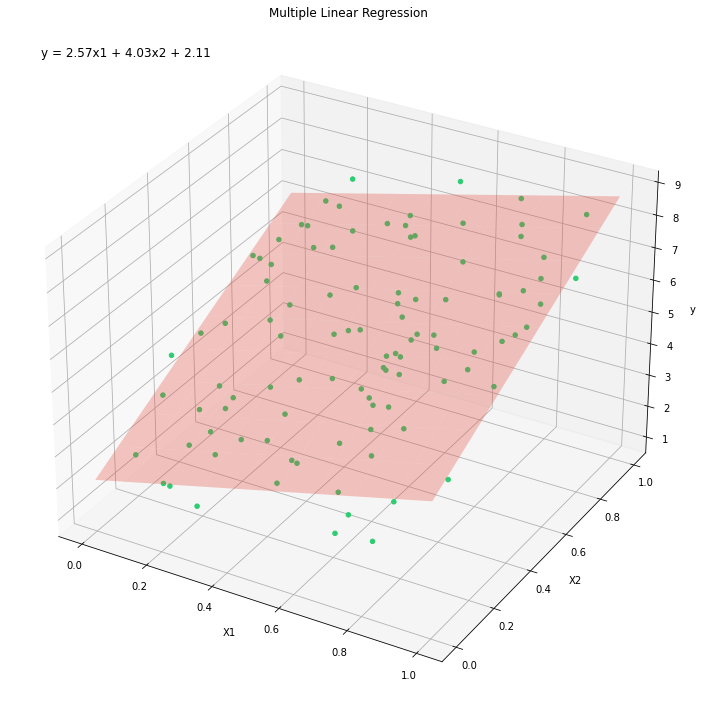

In [25]:
from mpl_toolkits.mplot3d import Axes3D

# Generate some random data for demonstration
np.random.seed(0)
X = np.random.rand(100, 2)
y = 2 + 3 * X[:, 0] + 4 * X[:, 1] + np.random.randn(100)

regression = LinearRegression()
regression.fit(X, y)

# Generate a grid of input values
x1_range = np.linspace(0, 1, 10)
x2_range = np.linspace(0, 1, 10)
x1_grid, x2_grid = np.meshgrid(x1_range, x2_range)
X_grid = np.c_[x1_grid.ravel(), x2_grid.ravel()]

predicted_y = regression.predict(X_grid)

fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X[:, 0], X[:, 1], y, color='#2ecc71', alpha=1, label='Original data')

# Plot the regression plane
ax.plot_surface(x1_grid, x2_grid, predicted_y.reshape(x1_grid.shape), color='#e74c3c', alpha=0.3, label='Regression plane')

ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('y')
ax.set_title('Multiple Linear Regression')
ax.grid(linestyle='dashed', alpha=0.5)

coef_1, coef_2 = regression.coef_
intercept = regression.intercept_
annotation_text = f'y = {coef_1:.2f}x1 + {coef_2:.2f}x2 + {intercept:.2f}'
ax.text2D(0.05, 0.95, annotation_text, transform=ax.transAxes, fontsize=12)

plt.tight_layout()
plt.show()


# Polynomial Regression

In [26]:
from sklearn.preprocessing import PolynomialFeatures

np.random.seed(0)
X = np.random.rand(5, 1)

poly_features = PolynomialFeatures(degree=3)
X_poly = poly_features.fit_transform(X)

print("Original features (X):")
print(X)
print()
print("Polynomial features (X_poly):")
print(X_poly)


Original features (X):
[[0.5488135 ]
 [0.71518937]
 [0.60276338]
 [0.54488318]
 [0.4236548 ]]

Polynomial features (X_poly):
[[1.         0.5488135  0.30119626 0.16530058]
 [1.         0.71518937 0.51149583 0.36581638]
 [1.         0.60276338 0.36332369 0.21899821]
 [1.         0.54488318 0.29689768 0.16177455]
 [1.         0.4236548  0.17948339 0.076039  ]]


In [27]:
np.random.seed(0)
X = np.random.rand(100, 1)
y = np.sin(2 * np.pi * X) + np.random.randn(100, 1) * 0.2

poly_features = PolynomialFeatures(degree=3)
X_poly = poly_features.fit_transform(X)

regression = LinearRegression()

regression.fit(X_poly, y)

LinearRegression()

In [28]:
X_poly.shape

(100, 4)

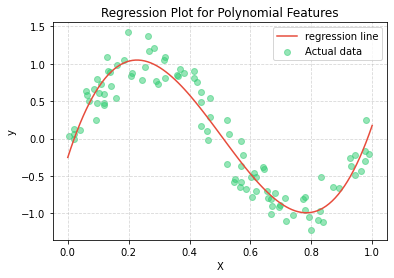

In [36]:
new_X = np.linspace(0, 1, 100).reshape(-1,1)
new_X_poly = poly_features.transform(new_X)
y_pred = regression.predict(new_X_poly)

# Plot the original data
plt.scatter(X, y, color='#2ecc71', alpha=0.5, label='Actual data')

# Plot the polynomial regression curve
plt.plot(new_X, y_pred, color='#e74c3c', label='regression line')

# Customize the plot appearance
plt.xlabel('X')
plt.ylabel('y')
plt.title('Regression Plot for Polynomial Features')
plt.legend()
plt.grid(linestyle='dashed', alpha=0.5)

# Show the plot
plt.show()

In [49]:
regression = LinearRegression()

regression.fit(X, y)

LinearRegression()

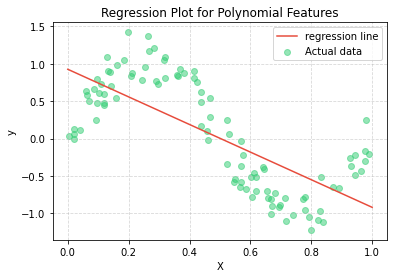

In [50]:
new_X = np.linspace(0, 1, 100).reshape(-1, 1)
y_pred = regression.predict(new_X)

# Plot the original data
plt.scatter(X, y, color='#2ecc71', alpha=0.5, label='Actual data')

# Plot the polynomial regression curve
plt.plot(new_X, y_pred, color='#e74c3c', label='regression line')

# Customize the plot appearance
plt.xlabel('X')
plt.ylabel('y')
plt.title('Regression Plot for Polynomial Features')
plt.legend()
plt.grid(linestyle='dashed', alpha=0.5)

# Show the plot
plt.show()

## Problem of polynomial features

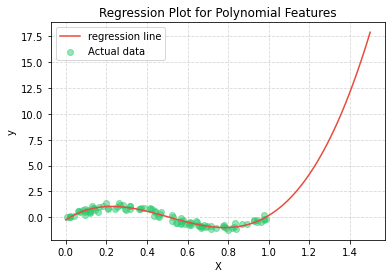

In [53]:
poly_features = PolynomialFeatures(degree=3)
X_poly = poly_features.fit_transform(X)

regression = LinearRegression()

regression.fit(X_poly, y)

new_X = np.linspace(0, 1.5, 100).reshape(-1, 1)
new_X_poly = poly_features.transform(new_X)
y_pred = regression.predict(new_X_poly)

# Plot the original data
plt.scatter(X, y, color='#2ecc71', alpha=0.5, label='Actual data')

# Plot the polynomial regression curve
plt.plot(new_X, y_pred, color='#e74c3c', label='regression line')

# Customize the plot appearance
plt.xlabel('X')
plt.ylabel('y')
plt.title('Regression Plot for Polynomial Features')
plt.legend()
plt.grid(linestyle='dashed', alpha=0.5)

# Show the plot
plt.show()

# Metrics

In [54]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [55]:
def print_metrics(y,y_pred):
    mse = mean_squared_error(y, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y, y_pred)
    r2 = r2_score(y, y_pred)
    mape = np.mean(np.abs((y - y_pred) / y)) * 100
    
    metrics = {
        'R-squared': r2,
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'MAPE': mape,
    }
    
    print("\n=== Regression Metrics ===")
    print(f"R-squared: {r2:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")


In [56]:
# Create Dataset
X, y = datasets.make_regression(n_samples=300, n_features=1, noise=20, random_state=41)
regression = LinearRegression()

regression.fit(X, y)

LinearRegression()

In [57]:
print_metrics(y,regression.predict(X))


=== Regression Metrics ===
R-squared: 0.9223
Mean Squared Error (MSE): 399.2048
Root Mean Squared Error (RMSE): 19.9801
Mean Absolute Error (MAE): 15.7837
Mean Absolute Percentage Error (MAPE): 91.95%


# Importance of Feature Engineering


=== Regression Metrics ===
R-squared: 0.0396
Mean Squared Error (MSE): 14.8842
Root Mean Squared Error (RMSE): 3.8580
Mean Absolute Error (MAE): 3.0183
Mean Absolute Percentage Error (MAPE): 135.57%
None

=== Regression Metrics ===
R-squared: 0.9839
Mean Squared Error (MSE): 0.2490
Root Mean Squared Error (RMSE): 0.4990
Mean Absolute Error (MAE): 0.4037
Mean Absolute Percentage Error (MAPE): 72.87%
None


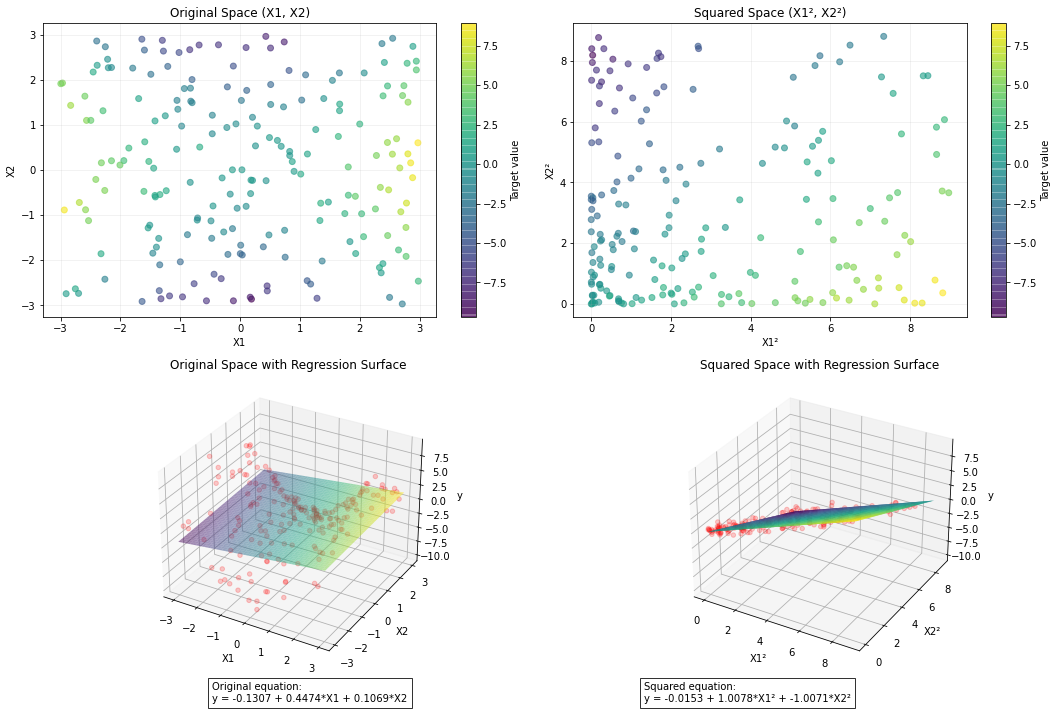


True relationship: y = X1² - X2² + noise

Original Space Function:
y = -0.1307 + 0.4474*X1 + 0.1069*X2

Squared Space Function:
y = -0.0153 + 1.0078*X1² + -1.0071*X2²


In [61]:
n_samples = 200
X1 = np.random.uniform(-3, 3, n_samples)
X2 = np.random.uniform(-3, 3, n_samples)
# True relationship: y = X1² - X2² + alpha
y = X1**2 - X2**2 + np.random.normal(0, 0.5, n_samples)

# Combine features
X = np.column_stack([X1, X2])

# Create squared features
X_squared = np.column_stack([X1**2, X2**2])

# Fit linear regression on original and squared features
reg_original = LinearRegression()
reg_squared = LinearRegression()

reg_original.fit(X, y)
reg_squared.fit(X_squared, y)

# Create figure with subplots
fig = plt.figure(figsize=(15, 10))

# 1. Original Space (2D)
ax1 = fig.add_subplot(221)
scatter1 = ax1.scatter(X1, X2, c=y, cmap='viridis', alpha=0.6)
ax1.set_title(f'Original Space (X1, X2)')
ax1.set_xlabel('X1')
ax1.set_ylabel('X2')
ax1.grid(True, alpha=0.2)
plt.colorbar(scatter1, ax=ax1, label='Target value')

# 2. Squared Space (2D)
ax2 = fig.add_subplot(222)
scatter2 = ax2.scatter(X1**2, X2**2, c=y, cmap='viridis', alpha=0.6)
ax2.set_title(f'Squared Space (X1², X2²)')
ax2.set_xlabel('X1²')
ax2.set_ylabel('X2²')
ax2.grid(True, alpha=0.2)
plt.colorbar(scatter2, ax=ax2, label='Target value')

# Create grid for 3D surface
x1_grid = np.linspace(X1.min(), X1.max(), 50)
x2_grid = np.linspace(X2.min(), X2.max(), 50)
xx1, xx2 = np.meshgrid(x1_grid, x2_grid)
X_grid = np.column_stack([xx1.ravel(), xx2.ravel()])
X_grid_squared = np.column_stack([xx1.ravel()**2, xx2.ravel()**2])

# Predict values for the grid
z_pred_original = reg_original.predict(X_grid).reshape(xx1.shape)
z_pred_squared = reg_squared.predict(X_grid_squared).reshape(xx1.shape)

print(print_metrics(y,reg_original.predict(X)))
print(print_metrics(y,reg_squared.predict(X_squared)))

# 3. Original Space (3D)
ax3 = fig.add_subplot(223, projection='3d')
# Plot the regression surface
surf1 = ax3.plot_surface(xx1, xx2, z_pred_original, cmap='viridis', alpha=0.5)
# Plot the scattered points
ax3.scatter(X1, X2, y, c='red', alpha=0.2)
ax3.set_title('Original Space with Regression Surface')
ax3.set_xlabel('X1')
ax3.set_ylabel('X2')
ax3.set_zlabel('y')

# 4. Squared Space (3D)
ax4 = fig.add_subplot(224, projection='3d')
# Plot the regression surface
surf2 = ax4.plot_surface(xx1**2, xx2**2, z_pred_squared, cmap='viridis', alpha=0.5)
# Plot the scattered points
ax4.scatter(X1**2, X2**2, y, c='red', alpha=0.2)
ax4.set_title('Squared Space with Regression Surface')
ax4.set_xlabel('X1²')
ax4.set_ylabel('X2²')
ax4.set_zlabel('y')

# Print equations
original_eq = f"y = {reg_original.intercept_:.4f} + {reg_original.coef_[0]:.4f}*X1 + {reg_original.coef_[1]:.4f}*X2"
squared_eq = f"y = {reg_squared.intercept_:.4f} + {reg_squared.coef_[0]:.4f}*X1² + {reg_squared.coef_[1]:.4f}*X2²"

# Add text boxes with equations
fig.text(0.2, 0.02, f"Original equation:\n{original_eq}", 
         bbox=dict(facecolor='white', alpha=0.8))
fig.text(0.6, 0.02, f"Squared equation:\n{squared_eq}", 
         bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

print("\nTrue relationship: y = X1² - X2² + noise")
print("\nOriginal Space Function:")
print(original_eq)
print("\nSquared Space Function:")
print(squared_eq)

# Underfitting vs Good Fitting vs Overfitting

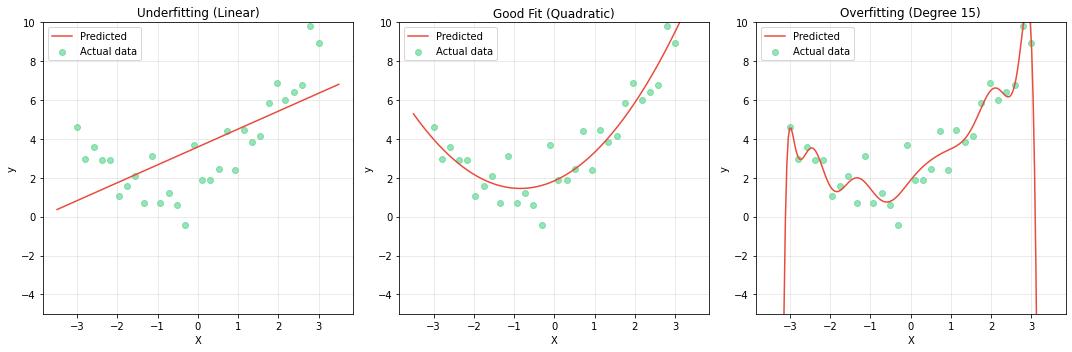

In [62]:
n_samples = 30
X = np.linspace(-3, 3, n_samples).reshape(-1, 1)
y = 0.5 * X.ravel()**2 + X.ravel() + 2 + np.random.normal(0, 1, size=n_samples)

degrees = [1, 2, 15]  # Underfit, Good fit, Overfit
titles = ['Underfitting (Linear)', 'Good Fit (Quadratic)', 'Overfitting (Degree 15)']

plt.figure(figsize=(15, 5))

# Create smooth X values for plotting
X_plot = np.linspace(-3.5, 3.5, 200).reshape(-1, 1)

for i, (degree, title) in enumerate(zip(degrees, titles), 1):
    poly_features = PolynomialFeatures(degree=degree)
    X_poly = poly_features.fit_transform(X)
    X_plot_poly = poly_features.transform(X_plot)
    
    model = LinearRegression()
    model.fit(X_poly, y)
    
    y_pred = model.predict(X_poly)
    y_plot = model.predict(X_plot_poly)
    
    
    plt.subplot(1, 3, i)
    plt.scatter(X.ravel(), y, color='#2ecc71', alpha=0.5, label='Actual data')
    plt.plot(X_plot.ravel(), y_plot, color='#e74c3c', label=f'Predicted ')
    
    plt.title(title)
    plt.xlabel('X')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.ylim(-5, 10)

plt.tight_layout()
plt.show()

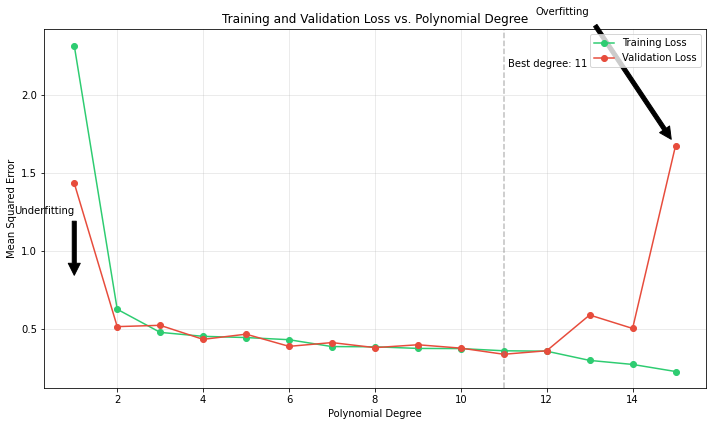


Best polynomial degree based on validation loss: 11


In [64]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

def plot_polynomial_loss(X, y, max_degree=15, test_size=0.2, random_state=42):
    # Split the data
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    
    # Initialize lists to store errors
    train_errors = []
    val_errors = []
    degrees = range(1, max_degree + 1)
    
    # Calculate errors for each polynomial degree
    for degree in degrees:
        # Create polynomial features
        poly_features = PolynomialFeatures(degree=degree)
        X_train_poly = poly_features.fit_transform(X_train)
        X_val_poly = poly_features.transform(X_val)
        
        # Fit model
        model = LinearRegression()
        model.fit(X_train_poly, y_train)
        
        # Calculate MSE for both sets
        train_pred = model.predict(X_train_poly)
        val_pred = model.predict(X_val_poly)
        
        train_mse = mean_squared_error(y_train, train_pred)
        val_mse = mean_squared_error(y_val, val_pred)
        
        train_errors.append(train_mse)
        val_errors.append(val_mse)
    
    # Create the plot
    plt.figure(figsize=(10, 6))
    plt.plot(degrees, train_errors, 'o-', color='#2ecc71', label='Training Loss')
    plt.plot(degrees, val_errors, 'o-', color='#e74c3c', label='Validation Loss')
    
    # Find the best degree (minimum validation error)
    best_degree = degrees[np.argmin(val_errors)]
    plt.axvline(x=best_degree, color='gray', linestyle='--', alpha=0.5)
    plt.text(best_degree + 0.1, plt.ylim()[1] * 0.9, 
             f'Best degree: {best_degree}', 
             rotation=0)
    
    plt.xlabel('Polynomial Degree')
    plt.ylabel('Mean Squared Error')
    plt.title('Training and Validation Loss vs. Polynomial Degree')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Add annotations for different regions
    plt.annotate('Underfitting', 
                xy=(1, np.mean(val_errors[:3])),
                xytext=(1, np.mean(val_errors[:3]) * 1.5),
                arrowprops=dict(facecolor='black', shrink=0.05),
                ha='right')
    
    plt.annotate('Overfitting', 
                xy=(max_degree, val_errors[-1]),
                xytext=(max_degree - 2, val_errors[-1] * 1.5),
                arrowprops=dict(facecolor='black', shrink=0.05),
                ha='right')
    
    plt.tight_layout()
    plt.show()
    
    return best_degree

n_samples = 30
X = np.linspace(-3, 3, n_samples).reshape(-1, 1)
y = 0.5 * X.ravel()**2 + X.ravel() + 2 + np.random.normal(0, 1, size=n_samples)

# Plot the loss curves
best_degree = plot_polynomial_loss(X, y, max_degree=15)
print(f"\nBest polynomial degree based on validation loss: {best_degree}")